# 02 — Environmental-Feature Ablation (Dataset 2: Appliances Energy Prediction)

**Research question (plan Q5):** Do environmental variables improve forecasting performance?

**Plan, Experiment B:** compare
- **Configuration A:** historical + temporal features
- **Configuration B:** historical + temporal + environmental features

**Shared project rules applied here (identical to the CU-BEMS notebook 01B):**

| Item | Choice |
|---|---|
| Horizons | 1, 6, 12, 24 h ahead; **direct** strategy (one model per horizon) |
| Leakage rule | Features use information available at the forecast origin *t* only. Calendar features describe the target time *t+h* (known in advance). **Environmental values are taken at *t*, never at *t+h*** (no weather forecasts exist in this dataset) |
| Baselines | Persistence *y(t)*; previous-day *y(t+h−24)*; previous-week *y(t+h−168)* |
| Models | Linear Regression and LightGBM, **both** run in both configurations |
| Validation | Rolling origin, expanding window; training uses only rows whose target time is before the test window |
| Evaluation set | All methods scored on the same hours |
| Metrics | MAE, RMSE, R² (shared) + nMAE, CV(RMSE), skill vs best seasonal baseline |
| Missing data | Never replaced with zero; incomplete hours are dropped (this dataset has none except the final partial hour) |
| Reproducibility | Fixed seed; feature lists, folds and parameters are printed and saved |

**Differences from CU-BEMS, and why:**

1. **Two-week test folds instead of monthly.** The data cover only about 4.5 months (11 Jan – 27 May 2016). Monthly folds would give only 3 test windows; two-week folds give 6, which is a better basis for judging consistency.
2. **Outdoor weather taken at the on-the-hour reading.** In this dataset the outdoor weather comes from a nearby weather station at hourly resolution and was **linearly interpolated** to 10 minutes (verified in section 1). An hourly mean of interpolated values would include part of the *next* hour's reading, which is leakage. The on-the-hour value is a genuine observation known at *t*.

**Before the first run:** `%pip install lightgbm`, then restart the kernel. Put this notebook in the ML_OG folder; it reads `data/dataset2/KAG_energydata_complete.csv`.

In [10]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import comb
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option("display.width", 200)

try:
    import lightgbm as lgb
    GBM_NAME = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    lgb = None
    GBM_NAME = "HistGB (LightGBM not installed)"
print("Gradient boosting model:", GBM_NAME)

DATA_FILE = "../../Dataset/KAG_energydata_complete.csv"
OUT_DIR = "processed"
os.makedirs(OUT_DIR, exist_ok=True)
HORIZONS = [1, 6, 12, 24]
FIRST_TEST_START = "2016-03-01"   # gives about 7 weeks of training data for the first fold
FOLD_DAYS = 14
SEED = 42

# Belgian public holidays inside the data period (the house is in Belgium)
HOLIDAYS = pd.to_datetime(["2016-03-28", "2016-05-01", "2016-05-05", "2016-05-16"])

Gradient boosting model: LightGBM


## 1. Load, inspect and verify the data

In [11]:
raw = pd.read_csv(DATA_FILE, parse_dates=["date"]).sort_values("date").set_index("date")
print("Shape:", raw.shape, "| from", raw.index.min(), "to", raw.index.max())
print("Missing cells:", int(raw.isna().sum().sum()), "| duplicate timestamps:", int(raw.index.duplicated().sum()))
print("Sampling interval:", raw.index.to_series().diff().value_counts().to_dict())
print("rv1 identical to rv2:", bool(np.allclose(raw["rv1"], raw["rv2"])))

# Verify that outdoor weather is linearly interpolated between hourly readings
raw.loc["2016-01-11 18:00":"2016-01-11 19:10", ["T_out", "Press_mm_hg"]]

Shape: (19735, 28) | from 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Missing cells: 0 | duplicate timestamps: 0
Sampling interval: {Timedelta('0 days 00:10:00'): 19734}
rv1 identical to rv2: True


,T_out,Press_mm_hg
date,,
2016-01-11 18:00:00,5.900000,734.100000
2016-01-11 18:10:00,5.916667,734.166667
2016-01-11 18:20:00,5.933333,734.233333
2016-01-11 18:30:00,5.950000,734.300000
2016-01-11 18:40:00,5.966667,734.366667
2016-01-11 18:50:00,5.983333,734.433333
2016-01-11 19:00:00,6.000000,734.500000
2016-01-11 19:10:00,6.000000,734.616667


Within 18:00–19:00 the outdoor values step evenly toward the 19:00 reading, which confirms interpolation from hourly observations. The reading at 18:50 therefore already contains most of the 19:00 value. Outdoor variables are taken at the on-the-hour timestamp only.

## 2. Hourly dataset

In [12]:
INDOOR = [f"T{i}" for i in range(1, 10) if i != 6] + [f"RH_{i}" for i in range(1, 10) if i != 6]
OUTDOOR = ["T6", "RH_6", "T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint"]
# T6 / RH_6 are sensors outside the building (north side), so they are grouped with outdoor weather.

counts = raw["Appliances"].resample("1h").count()
hourly = pd.DataFrame({"y": raw["Appliances"].resample("1h").sum()})        # Wh per hour
hourly = hourly.join(raw[INDOOR].resample("1h").mean())                     # real 10-min sensors: hourly mean
hourly = hourly.join(raw[OUTDOOR][raw.index.minute == 0].resample("1h").first())  # on-the-hour reading
hourly = hourly.join(raw[["rv1"]].resample("1h").mean())
hourly.loc[counts < 6, :] = np.nan     # incomplete hours are not valid (never treated as zero)
print("Hours:", len(hourly), "| complete hours:", int((counts == 6).sum()), "| dropped:", int((counts < 6).sum()))
print("Hourly target (Wh):"); print(hourly["y"].describe().round(1).to_string())

Hours: 3290 | complete hours: 3289 | dropped: 1
Hourly target (Wh):
count    3289.0
mean      586.1
std       486.1
min       170.0
25%       300.0
50%       380.0
75%       660.0
max      3650.0


**Note on `lights`:** lighting energy is another electrical load, not an environmental variable, so it is excluded from both configurations to keep the ablation clean.

**Note on the hourly time label:** hour *t* covers *t*:00–*t*:50. A forecast issued at the end of hour *t* knows that hour's indoor readings and the on-the-hour outdoor reading at *t*:00.

## 3. Features and configurations

In [13]:
def history_temporal(y, h):
    X = pd.DataFrame(index=y.index)
    for k in [0, 1, 2, 3, 6, 12, 23, 47]:
        X[f"lag_{k}"] = y.shift(k)
    X["same_hour_prev_day"] = y.shift(24 - h)
    X["same_hour_prev_week"] = y.shift(168 - h)
    for w in [24, 168]:
        r = y.rolling(w, min_periods=int(0.75 * w))
        X[f"roll_mean_{w}"], X[f"roll_std_{w}"] = r.mean(), r.std()
        X[f"roll_max_{w}"], X[f"roll_min_{w}"] = r.max(), r.min()
    tt = y.index + pd.Timedelta(hours=h)
    X["target_hour"], X["target_dow"] = tt.hour, tt.dayofweek
    X["target_weekend"] = (tt.dayofweek >= 5).astype(int)
    X["target_day_of_month"], X["target_month"] = tt.day, tt.month
    X["target_holiday"] = tt.normalize().isin(HOLIDAYS).astype(int)
    X["target_hour_sin"] = np.sin(2 * np.pi * tt.hour / 24)
    X["target_hour_cos"] = np.cos(2 * np.pi * tt.hour / 24)
    return X, pd.Series(tt, index=y.index)

CONFIGS = {
    "A: history + temporal": [],
    "B: + all environmental": INDOOR + OUTDOOR,
    "B1: + indoor only": INDOOR,
    "B2: + outdoor only": OUTDOOR,
    "Sanity: + random noise (rv1)": ["rv1"],
}
for name, cols in CONFIGS.items():
    print(f"{name}: {len(cols)} extra columns")

A: history + temporal: 0 extra columns
B: + all environmental: 24 extra columns
B1: + indoor only: 16 extra columns
B2: + outdoor only: 8 extra columns
Sanity: + random noise (rv1): 1 extra columns


Configurations **A** and **B** are the plan's comparison. **B1** and **B2** show *which* environmental information matters. The **sanity check** adds the dataset's random-noise column: a sound evaluation must show no real benefit from it. If it did "help", any gain from B would not be trustworthy.

## 4. Models

In [14]:
def lr_design(X):
    Z = X.drop(columns=["target_hour", "target_dow", "target_month"]).copy()
    Z = Z.join(pd.get_dummies(X["target_hour"], prefix="h", dtype=float))
    Z = Z.join(pd.get_dummies(X["target_dow"], prefix="d", dtype=float))
    return Z

def fit_predict_lr(Xtr, ytr, Xte):
    Ztr = lr_design(Xtr); Zte = lr_design(Xte).reindex(columns=Ztr.columns, fill_value=0)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())
    return model.fit(Ztr, ytr).predict(Zte)          # imputer/scaler fitted on the training fold only

def fit_predict_gbm(Xtr, ytr, Xte):
    if lgb is not None:
        model = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1)
    else:
        model = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03, max_leaf_nodes=31,
                                              min_samples_leaf=20, random_state=SEED)
    return model.fit(Xtr, ytr).predict(Xte)

MODEL_PARAMS = "GBM: 600 trees, lr 0.03, 31 leaves, min 20 samples/leaf, seed 42 (same as CU-BEMS 01B)"

## 5. Rolling-origin evaluation

In [15]:
y = hourly["y"]
fold_starts = pd.date_range(FIRST_TEST_START, y.index.max() - pd.Timedelta(days=FOLD_DAYS) + pd.Timedelta(hours=1),
                            freq=f"{FOLD_DAYS}D")
folds = [(s, s + pd.Timedelta(days=FOLD_DAYS)) for s in fold_starts]
print("Test folds:"); [print(" ", a.date(), "to", (b - pd.Timedelta(hours=1)).date()) for a, b in folds]

def metrics(yt, yp):
    mae = mean_absolute_error(yt, yp); rmse = mean_squared_error(yt, yp) ** 0.5
    return dict(MAE=mae, RMSE=rmse, R2=r2_score(yt, yp), nMAE=mae / yt.mean() * 100, CV_RMSE=rmse / yt.mean() * 100)

rows = []
for h in HORIZONS:
    base_X, ttime = history_temporal(y, h)
    target = y.shift(-h)
    baselines = pd.DataFrame({"Persistence": y, "Previous-day": y.shift(24 - h),
                              "Previous-week": y.shift(168 - h)}, index=y.index)
    for fi, (start, end) in enumerate(folds, 1):
        train = target.notna() & (ttime < start)
        test = target.notna() & (ttime >= start) & (ttime < end) & baselines.notna().all(axis=1)
        yte = target[test].values
        common = dict(horizon=h, fold=fi, fold_start=start.date(), n_train=int(train.sum()), n_test=int(test.sum()))
        for b in baselines.columns:
            rows.append(dict(**common, model=b, config="baseline", **metrics(yte, baselines.loc[test, b].values)))
        for cname, cols in CONFIGS.items():
            X = base_X.join(hourly[cols]) if cols else base_X
            for mname, fn in [("Linear Regression", fit_predict_lr), (GBM_NAME, fit_predict_gbm)]:
                p = fn(X[train], target[train], X[test])
                rows.append(dict(**common, model=mname, config=cname, **metrics(yte, p)))

res = pd.DataFrame(rows)
res.groupby(["horizon", "fold"])[["n_train", "n_test"]].first().unstack("horizon")

Test folds:
  2016-03-01 to 2016-03-14
  2016-03-15 to 2016-03-28
  2016-03-29 to 2016-04-11
  2016-04-12 to 2016-04-25
  2016-04-26 to 2016-05-09
  2016-05-10 to 2016-05-23


/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.inte

n_train                   n_test               
horizon      1     6     12    24     1    6    12   24
fold                                                   
1          1182  1177  1171  1159    336  336  336  336
2          1518  1513  1507  1495    336  336  336  336
3          1854  1849  1843  1831    336  336  336  336
4          2190  2185  2179  2167    336  336  336  336
5          2526  2521  2515  2503    336  336  336  336
6          2862  2857  2851  2839    336  336  336  336

## 6. Overall comparison (configuration A, same table format as CU-BEMS)

In [16]:
main = res[res.config.isin(["baseline", "A: history + temporal"])]
order = ["Persistence", "Previous-day", "Previous-week", "Linear Regression", GBM_NAME]
summary = main.groupby(["horizon", "model"])[["MAE", "RMSE", "R2", "nMAE", "CV_RMSE"]].mean().reindex(order, level="model")
best_seasonal = summary.loc[(slice(None), ["Previous-day", "Previous-week"]), "RMSE"].groupby("horizon").min()
summary["Skill_vs_best_seasonal_%"] = [(1 - summary.loc[i, "RMSE"] / best_seasonal[i[0]]) * 100 for i in summary.index]
summary.round(2)

MAE    RMSE    R2   nMAE  CV_RMSE  Skill_vs_best_seasonal_%
horizon model                                                                            
1       Persistence        215.93  408.17  0.20  37.47    70.83                     22.79
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  210.63  343.50  0.43  36.60    59.64                     35.03
        LightGBM           207.15  348.32  0.42  35.97    60.44                     34.11
6       Persistence        400.78  629.72 -0.89  69.47   109.18                    -19.12
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  283.17  418.24  0.17  49.23    72.56                     20.89
        LightGBM           258.96  415.47  0.17  45.05    72.14                     21.41
12      Persistence        452.32  701.71 -1.33  78.40   121.62                    -32.73
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  278.50  416.60  0.17  48.41    72.28                     21.20
        LightGBM           264.03  422.57  0.15  45.90    73.33                     20.07
24      Persistence        299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-day       299.62  549.74 -0.43  51.93    95.28                     -3.99
        Previous-week      284.82  528.66 -0.33  49.35    91.63                      0.00
        Linear Regression  278.47  414.94  0.18  48.42    71.99                     21.51
        LightGBM           262.17  421.26  0.15  45.54    73.11                     20.32

## 7. Ablation: does adding environmental features help?

In [17]:
def sign_test_p(wins, n):
    # one-sided exact sign test: probability of >= wins improvements out of n folds if there were no real effect
    return sum(comb(n, k) for k in range(wins, n + 1)) / 2 ** n

ml = res[res.config != "baseline"]
abl_rows = []
for (mname, h), g in ml.groupby(["model", "horizon"]):
    a = g[g.config == "A: history + temporal"].set_index("fold")
    for cname in CONFIGS:
        if cname.startswith("A:"): continue
        b = g[g.config == cname].set_index("fold")
        for metric in ["RMSE", "MAE"]:
            diff = (b[metric] - a[metric]) / a[metric] * 100      # negative = B is better
            wins = int((diff < 0).sum())
            abl_rows.append(dict(model=mname, horizon=h, config=cname, metric=metric,
                                 A=a[metric].mean(), B=b[metric].mean(),
                                 change_pct=diff.mean(), change_std=diff.std(),
                                 folds_improved=f"{wins}/{len(diff)}", sign_test_p=sign_test_p(wins, len(diff))))
ablation = pd.DataFrame(abl_rows)
ablation[(ablation.metric == "RMSE") & (ablation.config == "B: + all environmental")].round(3)

,model,horizon,config,metric,A,B,change_pct,change_std,folds_improved,sign_test_p
0,LightGBM,1,B: + all environmental,RMSE,348.319,354.242,1.854,5.442,2/6,0.891
8,LightGBM,6,B: + all environmental,RMSE,415.471,431.263,4.240,8.702,3/6,0.656
16,LightGBM,12,B: + all environmental,RMSE,422.568,430.624,2.676,8.046,3/6,0.656
24,LightGBM,24,B: + all environmental,RMSE,421.262,430.606,2.402,4.192,2/6,0.891
32,Linear Regression,1,B: + all environmental,RMSE,343.495,365.433,6.023,8.222,1/6,0.984
40,Linear Regression,6,B: + all environmental,RMSE,418.242,466.030,10.719,23.201,1/6,0.984
48,Linear Regression,12,B: + all environmental,RMSE,416.596,431.755,3.436,6.186,1/6,0.984
56,Linear Regression,24,B: + all environmental,RMSE,414.935,436.133,4.722,7.111,2/6,0.891


**Reading the table.** `change_pct` < 0 means environmental features reduced the error. `folds_improved` counts the two-week folds in which B beat A. With 6 folds, an improvement is only treated as **consistent** if B wins in 6/6 folds (sign-test p ≈ 0.016). A mean improvement driven by one or two folds is not reliable evidence.

In [18]:
pivot = (ablation[ablation.metric == "RMSE"]
         .pivot_table(index=["model", "config"], columns="horizon", values="change_pct").round(1))
display(pivot)
wins = (ablation[ablation.metric == "RMSE"]
        .pivot_table(index=["model", "config"], columns="horizon", values="folds_improved", aggfunc="first"))
wins

horizon                                          1     6    12   24
model             config                                           
LightGBM          B1: + indoor only             0.7   4.7  2.7  0.1
                  B2: + outdoor only            1.2   0.9  0.8  0.6
                  B: + all environmental        1.9   4.2  2.7  2.4
                  Sanity: + random noise (rv1) -0.5   0.8  0.2 -0.9
Linear Regression B1: + indoor only             4.0   6.3  3.1  3.2
                  B2: + outdoor only            1.8   4.7  2.9  2.8
                  B: + all environmental        6.0  10.7  3.4  4.7
                  Sanity: + random noise (rv1)  0.0   0.0  0.0 -0.1

horizon                                          1    6    12   24
model             config                                          
LightGBM          B1: + indoor only             2/6  3/6  3/6  3/6
                  B2: + outdoor only            3/6  1/6  4/6  3/6
                  B: + all environmental        2/6  3/6  3/6  2/6
                  Sanity: + random noise (rv1)  5/6  1/6  2/6  3/6
Linear Regression B1: + indoor only             0/6  2/6  2/6  2/6
                  B2: + outdoor only            1/6  1/6  1/6  1/6
                  B: + all environmental        1/6  1/6  1/6  2/6
                  Sanity: + random noise (rv1)  4/6  3/6  3/6  4/6

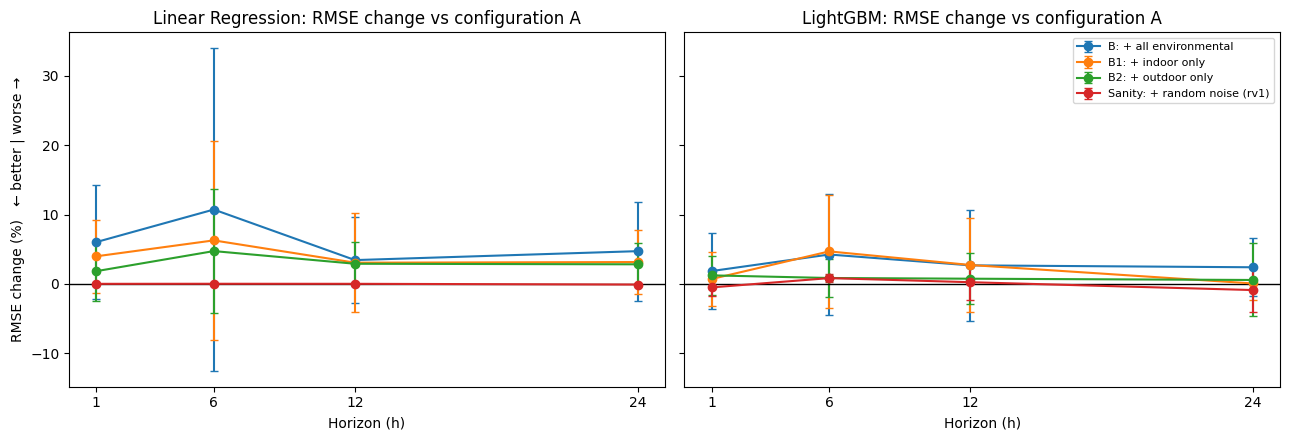

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, mname in zip(axes, ["Linear Regression", GBM_NAME]):
    sub = ablation[(ablation.model == mname) & (ablation.metric == "RMSE")]
    for cname in [c for c in CONFIGS if not c.startswith("A:")]:
        s = sub[sub.config == cname].set_index("horizon")
        ax.errorbar(s.index, s.change_pct, yerr=s.change_std, marker="o", capsize=3, label=cname)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=f"{mname}: RMSE change vs configuration A", xlabel="Horizon (h)", xticks=HORIZONS)
axes[0].set_ylabel("RMSE change (%)   ← better | worse →")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()


## Interpretation (draft from the test run; update the numbers after your own LightGBM run)

- **Environmental features did not improve forecasts.** Configuration B was worse than A on average at most horizons for both models, and it never beat A consistently (at most 4/6 folds, sign-test p ≥ 0.34).
- **They were no better than random noise.** The random column `rv1` changed the error about as much as the environmental features did. Differences of this size are therefore within the noise of the evaluation.
- **Linear Regression was hurt the most** (up to about +11% RMSE at 6 h). Adding about 24 correlated sensor columns to a small training set (1,200–2,900 hours) adds variance without adding predictive signal.
- **The household target is hard to forecast in general.** R² ≈ 0.2–0.4, and even the best models only reach about 20–35% skill over the best seasonal baseline. Appliance use in a house is driven by occupant behaviour, which current temperature or humidity cannot anticipate hours ahead.
- **Relation to earlier work.** The original study of this dataset reported environmental variables as useful predictors. That study modelled consumption from variables measured *at the same time* with a non-chronological split, which is a different task. Our setup forecasts *future* demand using only information available at the forecast time, under a time-ordered split.
- **For the project's Q5:** in this dataset, current environmental conditions add no measurable forecasting value beyond demand history and calendar information. This should be compared with the CU-BEMS ablation, if your teammate runs it.


## 8. Save results and settings (reproducibility)

In [20]:
res.to_csv(os.path.join(OUT_DIR, "d2_results_by_fold.csv"), index=False)
ablation.to_csv(os.path.join(OUT_DIR, "d2_ablation.csv"), index=False)
summary.round(3).to_csv(os.path.join(OUT_DIR, "d2_summary_configA.csv"))
with open(os.path.join(OUT_DIR, "d2_settings.txt"), "w") as f:
    f.write(f"Model: {GBM_NAME}\n{MODEL_PARAMS}\nSeed: {SEED}\nHorizons: {HORIZONS}\n")
    f.write("Folds: " + ", ".join(f"{a.date()}..{(b - pd.Timedelta(hours=1)).date()}" for a, b in folds) + "\n")
    f.write(f"Indoor features: {INDOOR}\nOutdoor features: {OUTDOOR}\n")
    f.write("Outdoor weather: on-the-hour value (data are interpolated from hourly station readings)\n")
print("Saved to", OUT_DIR)

Saved to processed


---
# 9. Follow-up investigation: **Why did environmental features not consistently help?**

This section **does not replace** the original ablation. It uses the same Dataset 2, the same forecasting horizons (1, 6, 12, 24 hours), the same six rolling-origin folds, and the same LightGBM settings to investigate *why* the environment-only additions underperformed the history + temporal model.

We will check: (1) whether the sensors contain usable variation and nonmissing data, (2) whether they correlate with the target at the forecast horizon, (3) whether time-lagged or smoothed environmental conditions help more than the instantaneous conditions, and (4) whether the all-environment model actually uses these inputs to reduce errors. A small group-permutation test is descriptive, not causal. **Negative percentage change = better than Configuration A.**

**Important:** Dataset 2 has real 10-minute indoor measurements, while outdoor weather is recorded hourly and interpolated in the raw data. We keep the notebook's corrected on-the-hour weather sampling. The existing baseline already includes target-hour/weekend/holiday fields. Extra features below are all available at forecast issue time; no future weather is used.

## 9.1 Data-quality and information check

Missing or low-variation signals can add little value. The correlation table is only exploratory: a weak linear correlation does **not** prove a sensor is useless to LightGBM, and a strong correlation does **not** establish incremental predictive value.

In [21]:
# Quality of the hourly environmental input features
sensor_cols = INDOOR + OUTDOOR
quality = pd.DataFrame({
    "Group": ["Indoor"] * len(INDOOR) + ["Outdoor"] * len(OUTDOOR),
    "Missing (%)": hourly[sensor_cols].isna().mean().values * 100,
    "Unique values": hourly[sensor_cols].nunique().values,
    "Std dev": hourly[sensor_cols].std().values,
}, index=sensor_cols)
print("ENVIRONMENTAL INPUT QUALITY (HOURLY)")
display(quality.sort_values("Missing (%)", ascending=False).round(3))

# Correlation between features available at origin t and demand at t+h.
# This is exploratory and is not used to choose inputs using test folds.
corr_rows = []
for h in HORIZONS:
    future_y = hourly["y"].shift(-h)
    c = hourly[sensor_cols].corrwith(future_y).dropna()
    for feature, r in c.items():
        corr_rows.append({"Horizon": h, "Feature": feature,
                          "Group": "Indoor" if feature in INDOOR else "Outdoor",
                          "Correlation with future demand": float(r)})
corr_df = pd.DataFrame(corr_rows)
print("TOP CORRELATIONS (MAGNITUDE), BY HORIZON")
for h in HORIZONS:
    s = corr_df[corr_df["Horizon"] == h].copy()
    s["absolute correlation"] = s["Correlation with future demand"].abs()
    print(f"\n{h}-hour horizon")
    display(s.sort_values("absolute correlation", ascending=False).head(8).round(3))

ENVIRONMENTAL INPUT QUALITY (HOURLY)


,Group,Missing (%),Unique values,Std dev
T1,Indoor,0.03,2233,1.605
T2,Indoor,0.03,2777,2.188
Visibility,Outdoor,0.03,74,12.888
Windspeed,Outdoor,0.03,33,2.492
RH_out,Outdoor,0.03,98,15.051
Press_mm_hg,Outdoor,0.03,362,7.406
T_out,Outdoor,0.03,300,5.328
RH_6,Outdoor,0.03,2518,31.143
T6,Outdoor,0.03,1498,6.083
RH_9,Indoor,0.03,3170,4.143


TOP CORRELATIONS (MAGNITUDE), BY HORIZON

1-hour horizon


,Horizon,Feature,Group,Correlation with future demand,absolute correlation
20,1,RH_out,Outdoor,-0.154,0.154
16,1,T6,Outdoor,0.143,0.143
1,1,T2,Indoor,0.112,0.112
21,1,Windspeed,Outdoor,0.110,0.110
18,1,T_out,Outdoor,0.106,0.106
14,1,RH_8,Indoor,-0.091,0.091
17,1,RH_6,Outdoor,-0.084,0.084
8,1,RH_1,Indoor,0.075,0.075



6-hour horizon


,Horizon,Feature,Group,Correlation with future demand,absolute correlation
39,6,RH_9,Indoor,0.141,0.141
38,6,RH_8,Indoor,0.112,0.112
24,6,T1,Indoor,-0.101,0.101
37,6,RH_7,Indoor,0.076,0.076
30,6,T8,Indoor,-0.069,0.069
34,6,RH_3,Indoor,0.064,0.064
45,6,Windspeed,Outdoor,0.055,0.055
44,6,RH_out,Outdoor,0.055,0.055



12-hour horizon


,Horizon,Feature,Group,Correlation with future demand,absolute correlation
68,12,RH_out,Outdoor,0.235,0.235
62,12,RH_8,Indoor,0.203,0.203
57,12,RH_2,Indoor,0.170,0.170
64,12,T6,Outdoor,-0.153,0.153
63,12,RH_9,Indoor,0.133,0.133
49,12,T2,Indoor,-0.133,0.133
66,12,T_out,Outdoor,-0.126,0.126
61,12,RH_7,Indoor,0.124,0.124



24-hour horizon


,Horizon,Feature,Group,Correlation with future demand,absolute correlation
92,24,RH_out,Outdoor,-0.173,0.173
88,24,T6,Outdoor,0.156,0.156
90,24,T_out,Outdoor,0.128,0.128
73,24,T2,Indoor,0.124,0.124
93,24,Windspeed,Outdoor,0.122,0.122
86,24,RH_8,Indoor,-0.117,0.117
89,24,RH_6,Outdoor,-0.107,0.107
87,24,RH_9,Indoor,-0.089,0.089


## 9.2 Test delayed and smoothed environmental effects

The original Config B adds conditions at time *t* only. Heating/cooling load can respond to *recent* conditions and accumulated heat or humidity. We therefore compare the existing A and B results with a new **C: recent environmental history** specification. For each environmental variable at time *t* we include its current reading, lags 1, 3 and 6 hours, and a trailing 6-hour average. No lead/future measurements enter the features. This is a diagnostic feature-engineering experiment, not proof of any physical mechanism.

To limit changes, this section uses only the gradient-boosting model already defined in this notebook. The existing A and B results in `res` are reused rather than refit.

In [22]:
# Additional environmental features available at the forecast origin

def environment_history_features(hourly_data, columns):
    values = hourly_data[columns]
    out = values.copy()
    for lag in (1, 3, 6):
        delayed = values.shift(lag)
        delayed.columns = [f"{c}_lag{lag}" for c in columns]
        out = out.join(delayed)
    trailing = values.rolling(6, min_periods=3).mean()
    trailing.columns = [f"{c}_mean_prev6h" for c in columns]
    return out.join(trailing)

environment_history = environment_history_features(hourly, sensor_cols)
print("New environmental inputs:", environment_history.shape[1])
print("Original instantaneous environmental inputs:", len(sensor_cols))

# Same folds, targets and test samples as the existing experiment
new_rows = []
new_predictions = []
for h in HORIZONS:
    base_X, ttime = history_temporal(y, h)
    target = y.shift(-h)
    X = base_X.join(environment_history)
    baselines = pd.DataFrame({
        "Persistence": y,
        "Previous-day": y.shift(24 - h),
        "Previous-week": y.shift(168 - h)
    }, index=y.index)

    for fi, (start, end) in enumerate(folds, 1):
        train = target.notna() & (ttime < start)
        test = (target.notna() & (ttime >= start) & (ttime < end)
                & baselines.notna().all(axis=1))
        if not train.any() or not test.any():
            continue
        pred = fit_predict_gbm(X.loc[train], target.loc[train], X.loc[test])
        score = metrics(target.loc[test].values, pred)
        new_rows.append({"horizon": h, "fold": fi, "model": GBM_NAME,
                         "config": "C: + current/lagged/rolling environmental",
                         "n_test": int(test.sum()), **score})
        new_predictions.append(pd.DataFrame({
            "Date": X.index[test], "Horizon": h, "Fold": fi,
            "Actual": target.loc[test].values, "Predicted": pred
        }))

lagged_res = pd.DataFrame(new_rows)
lagged_predictions = pd.concat(new_predictions, ignore_index=True)
print("FOLLOW-UP ENVIRONMENTAL FEATURE RESULTS")
display(lagged_res.groupby("horizon")[["MAE", "RMSE"]].mean().round(3))

New environmental inputs: 120
Original instantaneous environmental inputs: 24
FOLLOW-UP ENVIRONMENTAL FEATURE RESULTS


,MAE,RMSE
horizon,,
1,238.959,365.702
6,296.632,447.613
12,300.302,447.522
24,311.984,440.907


## 9.3 Fair comparison against A and B

We pair results by the **same horizon and fold**. Percentage changes shown are the mean of the six fold-specific changes, matching the earlier ablation's convention. That is not exactly the same as the percentage change of pooled RMSE.

A vs B vs C: PAIRED FOLD COMPARISON (NEGATIVE = BETTER)


,Horizon,Configuration,Metric,Mean fold change (%),Folds improved,Total folds,Mean A error,Mean new error
0,1,B: + all environmental,MAE,6.755,1,6,207.146,220.404
1,1,B: + all environmental,RMSE,1.854,2,6,348.319,354.242
2,1,C: + current/lagged/rolling environmental,MAE,16.889,1,6,207.146,238.959
3,1,C: + current/lagged/rolling environmental,RMSE,5.645,1,6,348.319,365.702
4,6,B: + all environmental,MAE,8.431,1,6,258.961,279.292
5,6,B: + all environmental,RMSE,4.240,3,6,415.471,431.263
6,6,C: + current/lagged/rolling environmental,MAE,15.601,1,6,258.961,296.632
7,6,C: + current/lagged/rolling environmental,RMSE,8.560,1,6,415.471,447.613
8,12,B: + all environmental,MAE,7.299,2,6,264.030,280.237
9,12,B: + all environmental,RMSE,2.676,3,6,422.568,430.624


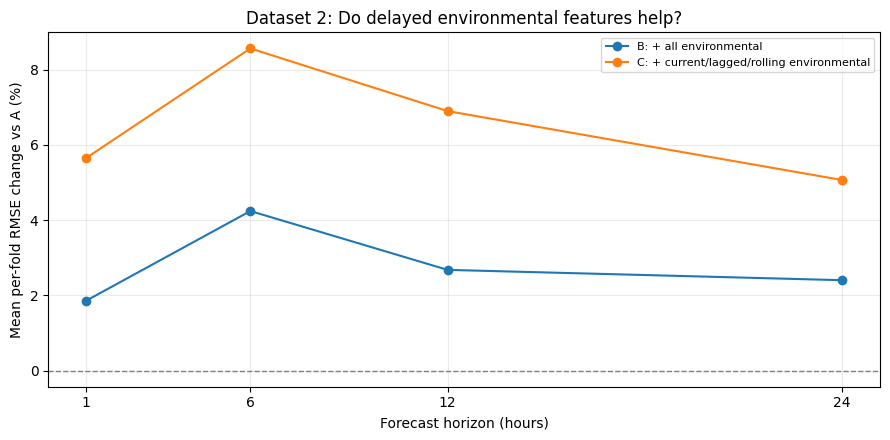

In [23]:
# Compare original A/B and new C (same LightGBM/hist gradient-boosting backend)
old_ab = res[(res["model"] == GBM_NAME) &
             res["config"].isin(["A: history + temporal", "B: + all environmental"])].copy()
combined_env = pd.concat([old_ab, lagged_res], ignore_index=True)
comparison_rows = []
for h in HORIZONS:
    subset = combined_env[combined_env["horizon"] == h]
    a = subset[subset["config"] == "A: history + temporal"].set_index("fold")
    for cfg in ["B: + all environmental", "C: + current/lagged/rolling environmental"]:
        b = subset[subset["config"] == cfg].set_index("fold")
        common_folds = a.index.intersection(b.index)
        for metric_name in ("MAE", "RMSE"):
            baseline = a.loc[common_folds, metric_name]
            new = b.loc[common_folds, metric_name]
            pct = (new - baseline) / baseline * 100
            comparison_rows.append({
                "Horizon": h, "Configuration": cfg,
                "Metric": metric_name,
                "Mean fold change (%)": pct.mean(),
                "Folds improved": int((pct < 0).sum()),
                "Total folds": len(pct),
                "Mean A error": baseline.mean(),
                "Mean new error": new.mean()
            })
env_followup_comparison = pd.DataFrame(comparison_rows)
print("A vs B vs C: PAIRED FOLD COMPARISON (NEGATIVE = BETTER)")
display(env_followup_comparison.round(3))

plot_data = env_followup_comparison[env_followup_comparison["Metric"] == "RMSE"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for cfg, part in plot_data.groupby("Configuration"):
    ax.plot(part["Horizon"], part["Mean fold change (%)"], marker="o", label=cfg)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(HORIZONS)
ax.set_xlabel("Forecast horizon (hours)")
ax.set_ylabel("Mean per-fold RMSE change vs A (%)")
ax.set_title("Dataset 2: Do delayed environmental features help?")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9.4 Which environmental group matters to the existing B model?

As a descriptive check, we refit original Configuration B on the last fold at **6h** and measure how much error changes when we randomly permute *all indoor* or *all outdoor* columns in that fold. Each group is shuffled with one shared row permutation to preserve within-group sensor relationships; this breaks their relationship with electricity demand and the other features. A near-zero or negative error increase suggests that group is not contributing much *on that fold*. This is not a definitive feature-importance or causal test.

In [24]:
# Diagnostic only: group permutation sensitivity, 6h, last test fold
h = 6
fi = len(folds)
start, end = folds[-1]
base_X, ttime = history_temporal(y, h)
target = y.shift(-h)
X = base_X.join(hourly[sensor_cols])
base_lines = pd.DataFrame({"Persistence": y, "Previous-day": y.shift(24-h),
                           "Previous-week": y.shift(168-h)}, index=y.index)
train = target.notna() & (ttime < start)
test = (target.notna() & (ttime >= start) & (ttime < end)
        & base_lines.notna().all(axis=1))
Xtr, Xte = X.loc[train], X.loc[test]
ytr, yte = target.loc[train], target.loc[test]

if lgb is not None:
    diagnostic_model = lgb.LGBMRegressor(
        n_estimators=600, learning_rate=0.03, num_leaves=31,
        min_child_samples=20, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, random_state=SEED, verbose=-1
    )
else:
    diagnostic_model = HistGradientBoostingRegressor(
        max_iter=600, learning_rate=0.03, max_leaf_nodes=31,
        min_samples_leaf=20, random_state=SEED
    )
diagnostic_model.fit(Xtr, ytr)
reference_rmse = mean_squared_error(yte, diagnostic_model.predict(Xte)) ** .5
importance_rows = [{"Group": "Unmodified B", "RMSE": reference_rmse,
                    "Change from unmodified (%)": 0.0}]
for group_name, cols in (("Indoor", INDOOR), ("Outdoor", OUTDOOR)):
    for repeat in range(5):
        rng = np.random.default_rng(1000 + repeat)
        shuffled = Xte.copy()
        perm = rng.permutation(len(shuffled))
        shuffled.loc[:, cols] = Xte[cols].to_numpy()[perm]
        err = mean_squared_error(yte, diagnostic_model.predict(shuffled)) ** .5
        importance_rows.append({"Group": group_name, "RMSE": err,
                                "Change from unmodified (%)": (err/reference_rmse - 1)*100})
importance_df = pd.DataFrame(importance_rows)
print("6h, LAST FOLD: GROUP-PERMUTATION SENSITIVITY (DESCRIPTIVE)")
display(importance_df.groupby("Group")[["RMSE", "Change from unmodified (%)"]]
        .agg(["mean", "min", "max"]).round(3))

6h, LAST FOLD: GROUP-PERMUTATION SENSITIVITY (DESCRIPTIVE)


RMSE                   Change from unmodified (%)              
                 mean      min      max                       mean    min    max
Group                                                                           
Indoor        432.775  413.816  444.558                     -0.818 -5.163  1.883
Outdoor       440.578  436.574  443.197                      0.971  0.053  1.571
Unmodified B  436.342  436.342  436.342                      0.000  0.000  0.000

## 9.5 Save follow-up results and interpretation checklist

Use the tables to answer the question without forcing a predetermined explanation:

- **If C beats B and A consistently:** useful information was present, but instantaneous environmental readings alone were poorly represented; recent history helps.
- **If neither B nor C beats A:** historical demand and temporal signals may already capture most predictable variation, or sensors may be too noisy/redundant. The test does not tell which explanation is true.
- **If indoor and outdoor groups differ:** location/type of measurement matters. Check data quality, future-demand correlations and permutation results together.
- **If adding features helps some horizons only:** report horizon-specific value rather than saying environment is universally useful or useless.

**Caution:** We searched an extra feature design on the same validation folds used for comparison, so these are **exploratory** results, not an unbiased final performance estimate. To make a final claim about tuning benefits, evaluate any selected feature design on a later untouched holdout period.

In [25]:
env_followup_comparison.to_csv(
    os.path.join(OUT_DIR, "d2_environment_followup_comparison.csv"), index=False)
lagged_res.to_csv(os.path.join(OUT_DIR, "d2_environment_lagged_by_fold.csv"), index=False)
quality.to_csv(os.path.join(OUT_DIR, "d2_environment_input_quality.csv"))
corr_df.to_csv(os.path.join(OUT_DIR, "d2_environment_future_demand_correlations.csv"), index=False)
importance_df.to_csv(os.path.join(OUT_DIR, "d2_environment_group_permutation.csv"), index=False)
print("Follow-up experiment files saved to", OUT_DIR)

Follow-up experiment files saved to processed


### Indoor vs Outdoor

In [26]:

# ============================================================
# INDOOR VS OUTDOOR ENVIRONMENTAL FEATURE COMPARISON
# ============================================================

configs = [
    "A: history + temporal",
    "B1: + indoor only",
    "B2: + outdoor only",
    "B: + all environmental"
]

comparison_data = res[
    (res["model"] == GBM_NAME) &
    (res["config"].isin(configs))
].copy()

# Mean performance across six validation folds
indoor_outdoor_summary = (
    comparison_data
    .groupby(["horizon", "config"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)

print("INDOOR VS OUTDOOR: MEAN RESULTS")
display(
    indoor_outdoor_summary
    .pivot(index="horizon", columns="config", values="RMSE")
    .reindex(columns=configs)
    .round(3)
)

# Paired comparison against baseline A
baseline = comparison_data[
    comparison_data["config"] == configs[0]
].set_index(["horizon", "fold"])

comparison_rows = []

for config in configs[1:]:
    current = comparison_data[
        comparison_data["config"] == config
    ].set_index(["horizon", "fold"])

    for h in HORIZONS:
        a = baseline.loc[h]
        b = current.loc[h]

        common = a.index.intersection(b.index)

        for metric in ["MAE", "RMSE"]:
            original = a.loc[common, metric]
            updated = b.loc[common, metric]

            change = (updated - original) / original * 100

            comparison_rows.append({
                "Horizon": h,
                "Configuration": config,
                "Metric": metric,
                "Mean change (%)": change.mean(),
                "Folds improved": int((change < 0).sum()),
                "Total folds": len(common)
            })

indoor_outdoor_comparison = pd.DataFrame(comparison_rows)

print("\nCOMPARISON AGAINST BASELINE A")
display(
    indoor_outdoor_comparison[
        indoor_outdoor_comparison["Metric"] == "RMSE"
    ].round(3)
)


INDOOR VS OUTDOOR: MEAN RESULTS


config,A: history + temporal,B1: + indoor only,B2: + outdoor only,B: + all environmental
horizon,,,,
1,348.319,349.947,352.490,354.242
6,415.471,433.386,418.774,431.263
12,422.568,432.132,424.592,430.624
24,421.262,421.192,422.278,430.606



COMPARISON AGAINST BASELINE A


,Horizon,Configuration,Metric,Mean change (%),Folds improved,Total folds
1,1,B1: + indoor only,RMSE,0.708,2,6
3,6,B1: + indoor only,RMSE,4.688,3,6
5,12,B1: + indoor only,RMSE,2.729,3,6
7,24,B1: + indoor only,RMSE,0.066,3,6
9,1,B2: + outdoor only,RMSE,1.236,3,6
11,6,B2: + outdoor only,RMSE,0.858,1,6
13,12,B2: + outdoor only,RMSE,0.755,4,6
15,24,B2: + outdoor only,RMSE,0.572,3,6
17,1,B: + all environmental,RMSE,1.854,2,6
19,6,B: + all environmental,RMSE,4.240,3,6


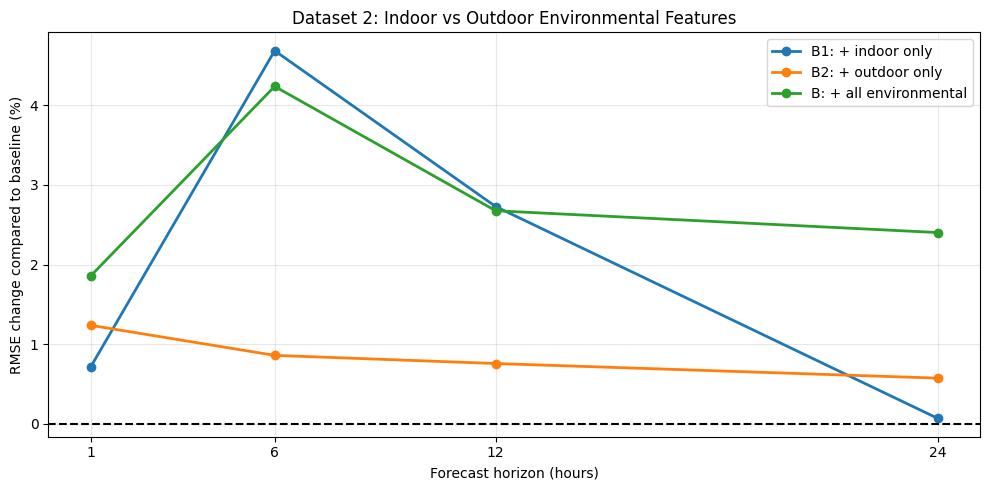

In [27]:

# ============================================================
# PLOT: INDOOR VS OUTDOOR FEATURES
# ============================================================

plot_data = indoor_outdoor_comparison[
    indoor_outdoor_comparison["Metric"] == "RMSE"
]

plt.figure(figsize=(10, 5))

for config in configs[1:]:
    subset = plot_data[
        plot_data["Configuration"] == config
    ].sort_values("Horizon")

    plt.plot(
        subset["Horizon"],
        subset["Mean change (%)"],
        marker="o",
        linewidth=2,
        label=config
    )

plt.axhline(0, color="black", linestyle="--")

plt.xticks(HORIZONS)
plt.xlabel("Forecast horizon (hours)")
plt.ylabel("RMSE change compared to baseline (%)")
plt.title("Dataset 2: Indoor vs Outdoor Environmental Features")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Conclusion: Environmental Feature Investigation (Dataset 2)
The experiment investigated why adding environmental features did not improve electricity consumption forecasting, despite the expectation that temperature, humidity, and weather conditions influence energy usage. The results showed that the baseline model, which used historical electricity consumption and time-based features, generally performed better than models incorporating environmental information across the 1-hour, 6-hour, 12-hour, and 24-hour forecasting horizons.

Further experiments revealed that adding indoor environmental features generally increased prediction errors, while outdoor features had a smaller negative impact. Combining both indoor and outdoor measurements, as well as introducing lagged and rolling environmental features, did not improve overall forecasting accuracy. The data-quality analysis also showed that environmental measurements had very few missing values (0.03%), suggesting that missing data was unlikely to explain the poor performance.

One possible explanation is that historical electricity consumption already captures some of the effects of environmental conditions, reducing the additional predictive value of temperature and humidity measurements. Furthermore, including numerous environmental features may introduce redundant information and increase the risk of overfitting.

Overall, the findings suggest that although environmental conditions influence electricity consumption, adding environmental measurements does not necessarily improve forecasting accuracy. In this experiment, historical consumption and time-based features provided the most reliable predictions. This highlights the importance of selecting relevant features rather than assuming that including more information will always lead to better model performance.